In [558]:
# https://github.com/jeandeducla/ML-Time-Series/blob/master/SVM-Accelerometer.ipynb
import pandas as pd
import numpy as np
import datetime as dt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor

In [559]:
import scipy.stats as st
from scipy.fftpack import fft, fftfreq 
from scipy.signal import argrelextrema
import operator

In [647]:
df1=pd.read_csv('database_gas.csv')

In [648]:
df1.head()

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue
0,2019-11-06 11:37:13.038174+01:00,19.48,54.86,128.0,563.0,476.0,731.0,649.0,565.0,128.0
1,2019-11-06 11:37:32.744996+01:00,19.59,54.23,129.0,563.0,477.0,731.0,649.0,565.0,125.0
2,2019-11-06 11:37:53.018087+01:00,19.63,54.05,128.0,566.0,478.0,732.0,649.0,565.0,125.0
3,2019-11-06 11:38:13.093151+01:00,19.64,53.74,128.0,566.0,478.0,732.0,649.0,565.0,125.0
4,2019-11-06 11:38:33.032832+01:00,19.67,53.53,128.0,569.0,480.0,732.0,650.0,565.0,125.0


In [649]:
df2=pd.read_csv('data_ref_until_2020-02-13.csv')

In [650]:
df2.head()

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue
0,2020-01-25 00:01:49.251503+01:00,20.64,55.57,121.0,496.0,521.0,694.0,652.0,591.0,135.0
1,2020-01-25 00:02:09.350082+01:00,20.64,55.53,122.0,495.0,521.0,694.0,652.0,591.0,135.0
2,2020-01-25 00:02:29.319505+01:00,20.62,55.53,121.0,495.0,522.0,694.0,651.0,591.0,135.0
3,2020-01-25 00:02:49.399379+01:00,20.62,55.57,121.0,495.0,522.0,694.0,651.0,591.0,135.0
4,2020-01-25 00:03:09.158989+01:00,20.62,55.59,121.0,495.0,522.0,694.0,652.0,591.0,135.0


In [651]:
df1['timestamp'] = pd.to_datetime(df1['timestamp'])

# Remove timezone information to make all datetime objects timezone-naive
df1['timestamp'] = df1['timestamp'].dt.tz_localize(None)

In [652]:
df2['timestamp'] = pd.to_datetime(df2['timestamp'])

# Remove timezone information to make all datetime objects timezone-naive
df2['timestamp'] = df2['timestamp'].dt.tz_localize(None)

# Define the time period to exclude
exclude_start = pd.Timestamp('2020-01-29 15:00:00')
exclude_end = exclude_start + pd.Timedelta(hours=1)

# Filter out the data from 2020-01-29 at 15
df2 = df2[~((df2['timestamp'] >= exclude_start) & (df2['timestamp'] < exclude_end))]

# Replace the year 2020 with 2021 in the specified date range
start_replace = pd.Timestamp('2020-01-25')
end_replace = pd.Timestamp('2020-02-13 23:59:59')

df2['timestamp'] = df2['timestamp'].apply(lambda x: x.replace(year=2021) if start_replace <= x <= end_replace else x)

In [653]:
df2.tail(10)

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue
75501,2021-02-13 11:55:13.930613,20.72,57.59,62.0,517.0,525.0,699.0,642.0,591.0,155.0
75502,2021-02-13 11:55:33.951730,20.69,57.66,62.0,517.0,525.0,699.0,642.0,591.0,156.0
75503,2021-02-13 11:55:54.065586,20.69,57.69,62.0,517.0,525.0,699.0,642.0,591.0,156.0
75504,2021-02-13 11:56:14.043796,20.62,57.75,62.0,518.0,525.0,698.0,642.0,591.0,156.0
75505,2021-02-13 11:56:34.223559,20.62,57.75,62.0,518.0,524.0,698.0,642.0,591.0,157.0
75506,2021-02-13 11:56:53.929978,20.62,57.75,62.0,518.0,524.0,698.0,642.0,591.0,157.0
75507,2021-02-13 11:57:14.204458,20.62,57.75,62.0,518.0,524.0,698.0,641.0,591.0,157.0
75508,2021-02-13 11:57:33.983249,20.62,57.75,62.0,518.0,524.0,698.0,641.0,591.0,157.0
75509,2021-02-13 11:57:54.058349,20.62,57.74,63.0,518.0,524.0,698.0,641.0,591.0,157.0
75510,2021-02-13 11:58:14.014336,20.62,57.74,63.0,518.0,524.0,698.0,641.0,591.0,157.0


In [654]:
#marge two dataset
frame=[df1,df2]
df=pd.concat(frame)

In [655]:
df.to_csv('final_db.csv')

In [656]:
# need to convert time string to time format for easy processing
df['recordtime'] = df['timestamp']
df.recordtime =df.recordtime.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
df.recordtime =df.recordtime.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [657]:
# sort values from small time to large time
# how much signal is difference from the prevous time to current time is important
df.sort_values(by='recordtime', inplace=True, ascending=True)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['timestamp'] = df['timestamp'].dt.floor(freq='30T')

In [658]:
exclude_start = pd.Timestamp('2020-01-29 15:00:00')
exclude_end = pd.Timestamp('2020-01-29 15:59:59')

# Exclude the data in the specified time range
df = df[~((df['recordtime'] >= exclude_start) & (df['recordtime'] <= exclude_end))]

# Optional: Reset the index after filtering
df.reset_index(drop=True, inplace=True)

In [659]:
# always check the latest data
df.head()

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue,recordtime
0,2019-11-06 11:30:00,19.48,54.86,128.0,563.0,476.0,731.0,649.0,565.0,128.0,2019-11-06 11:37:13
1,2019-11-06 11:30:00,19.59,54.23,129.0,563.0,477.0,731.0,649.0,565.0,125.0,2019-11-06 11:37:32
2,2019-11-06 11:30:00,19.63,54.05,128.0,566.0,478.0,732.0,649.0,565.0,125.0,2019-11-06 11:37:53
3,2019-11-06 11:30:00,19.64,53.74,128.0,566.0,478.0,732.0,649.0,565.0,125.0,2019-11-06 11:38:13
4,2019-11-06 11:30:00,19.67,53.53,128.0,569.0,480.0,732.0,650.0,565.0,125.0,2019-11-06 11:38:33


In [660]:
df.tail()

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue,recordtime
491299,2021-02-13 11:30:00,20.62,57.75,62.0,518.0,524.0,698.0,642.0,591.0,157.0,2021-02-13 11:56:53
491300,2021-02-13 11:30:00,20.62,57.75,62.0,518.0,524.0,698.0,641.0,591.0,157.0,2021-02-13 11:57:14
491301,2021-02-13 11:30:00,20.62,57.75,62.0,518.0,524.0,698.0,641.0,591.0,157.0,2021-02-13 11:57:33
491302,2021-02-13 11:30:00,20.62,57.74,63.0,518.0,524.0,698.0,641.0,591.0,157.0,2021-02-13 11:57:54
491303,2021-02-13 11:30:00,20.62,57.74,63.0,518.0,524.0,698.0,641.0,591.0,157.0,2021-02-13 11:58:14


In [661]:
df.shape

(491304, 11)

In [662]:
# look the count for each time group
group_count = pd.DataFrame(df.groupby('timestamp').count()['humidity'])
group_count.reset_index(inplace=True)
group_count.rename(columns={"humidity": "countv"}, inplace=True)

In [663]:
# some of the time group has low number of data missing
# Fillup them
group_count.countv.unique()

array([69, 90, 89, 91, 87, 80,  5,  2, 50, 31, 82, 72, 88, 81, 85, 35, 67,
       74, 36, 84, 62, 58, 47,  4, 55, 61, 37])

In [664]:
# these time group has low count - 
# lot of data is missing for these. So they need to be removed
time_low_count = group_count[group_count.countv<75]
time_low_count

,timestamp,countv
0,2019-11-06 11:30:00,69
1553,2019-12-08 20:00:00,5
1554,2019-12-09 10:30:00,2
1555,2019-12-09 11:00:00,50
1556,2019-12-09 11:30:00,31
2041,2019-12-19 14:00:00,72
3834,2020-01-25 22:30:00,35
3835,2020-01-25 23:00:00,67
3842,2020-01-26 02:30:00,74
3850,2020-01-26 06:30:00,72


In [665]:
# np.unique([(list(df.recordtime)[i] - list(df.recordtime)[i-1]).seconds for i in range(1, len(df.recordtime))])

In [666]:
df.columns

Index(['timestamp', 'temperature', 'humidity', 'CO2CosIRValue',
       'CO2MG811Value', 'MOX1', 'MOX2', 'MOX3', 'MOX4', 'COValue',
       'recordtime'],
      dtype='object')

In [667]:
# investigate how these data is missing
processed_df = df[['temperature', 'humidity', 'CO2CosIRValue','CO2MG811Value', 'MOX1', 'MOX4', 'COValue']].copy()
processed_df['timestamp'] = df['timestamp']
processed_df['recordtime'] = df['recordtime']

In [668]:
processed_df=processed_df[~processed_df.timestamp.isin(time_low_count.timestamp)]

In [669]:
processed_df.shape

(489759, 9)

In [670]:
group_count = group_count[~group_count.timestamp.isin(time_low_count.timestamp)]

In [671]:
group_count.shape

(5443, 2)

In [672]:
def stat_area_features(x, Te=1.0):

    mean_ts = np.mean(x, axis=1).reshape(-1,1) # mean
    max_ts = np.amax(x, axis=1).reshape(-1,1) # max
    min_ts = np.amin(x, axis=1).reshape(-1,1) # min
    std_ts = np.std(x, axis=1).reshape(-1,1) # std
    skew_ts = st.skew(x, axis=1).reshape(-1,1) # skew
    kurtosis_ts = st.kurtosis(x, axis=1).reshape(-1,1) # kurtosis 
    iqr_ts = st.iqr(x, axis=1).reshape(-1,1) # interquartile rante
    mad_ts = np.median(np.sort(abs(x - np.median(x, axis=1).reshape(-1,1)),
                               axis=1), axis=1).reshape(-1,1) # median absolute deviation
    area_ts = np.trapz(x, axis=1, dx=Te).reshape(-1,1) # area under curve
    sq_area_ts = np.trapz(x ** 2, axis=1, dx=Te).reshape(-1,1) # area under curve ** 2

    return np.concatenate((mean_ts,max_ts,min_ts,std_ts,skew_ts,kurtosis_ts,
                           iqr_ts,mad_ts,area_ts,sq_area_ts), axis=1)

In [673]:
def frequency_domain_features(x, Te=1.0):

    # As the DFT coefficients and their corresponding frequencies are symetrical arrays
    # with respect to the middle of the array we need to know if the number of readings 
    # in x is even or odd to then split the arrays...
    if x.shape[1]%2 == 0:
        N = int(x.shape[1]/2)
    else:
        N = int(x.shape[1]/2) - 1
    xf = np.repeat(fftfreq(x.shape[1],d=Te)[:N].reshape(1,-1), x.shape[0], axis=0) # frequencies
    dft = np.abs(fft(x, axis=1))[:,:N] # DFT coefficients   
    
    # statistical and area features
    dft_features = stat_area_features(dft, Te=1.0)
    # weighted mean frequency
    dft_weighted_mean_f = np.average(xf, axis=1, weights=dft).reshape(-1,1)
    # 5 first DFT coefficients 
    dft_first_coef = dft[:,:5]    
    # 5 first local maxima of DFT coefficients and their corresponding frequencies
    dft_max_coef = np.zeros((x.shape[0],5))
    dft_max_coef_f = np.zeros((x.shape[0],5))
    for row in range(x.shape[0]):
        # finds all local maximas indexes
        extrema_ind = argrelextrema(dft[row,:], np.greater, axis=0) 
        # makes a list of tuples (DFT_i, f_i) of all the local maxima
        # and keeps the 5 biggest...
        extrema_row = sorted([(dft[row,:][j],xf[row,j]) for j in extrema_ind[0]],
                             key=operator.itemgetter(0), reverse=True)[:5] 
        for i, ext in enumerate(extrema_row):
            dft_max_coef[row,i] = ext[0]
            dft_max_coef_f[row,i] = ext[1]    
    
    return np.concatenate((dft_features,dft_weighted_mean_f,dft_first_coef,
                           dft_max_coef,dft_max_coef_f), axis=1)


In [680]:
def convert_to_list(data, column_name):
    Unique_time = data.timestamp.unique()
    X = []
    for time in Unique_time:
        values = data[data.timestamp==time][column_name].tolist()
        if len(values)<91:
            resample_len=91-len(values)
            new_data = [np.mean(values)] * resample_len
            values.extend(new_data)
        X.append(values)
    return np.array(X)

In [681]:
def make_feature(data, column_name, Te=1.0):
    # convert data into list of lists
    x=convert_to_list(data, column_name)

    # extract statistical feature
    x_stat=stat_area_features(x)
    x_stat=pd.DataFrame(x_stat)
    x_stat.columns=[column_name+'_stat_'+ str(i) for i in range(x_stat.shape[1])]

    # extract statistical feature for the signal difference
    xt_jerk = stat_area_features((x[:, 1:]-x[:, :-1])/Te, Te=Te)
    xt_jerk = pd.DataFrame(xt_jerk)
    xt_jerk.columns=[column_name + '_xt_jerk_' + str(i) for i in range(xt_jerk.shape[1])]
    x_final=pd.concat([x_stat, xt_jerk], axis=1)

    
    # extract frequency_domain_features
    x_domain=frequency_domain_features(x)
    x_domain=pd.DataFrame(x_domain)
    x_domain.columns=[column_name +'_tm_dom_'+ str(i) for i in range(x_domain.shape[1])]
    x_final = pd.concat([x_final, x_domain], axis=1)

    # extract frequency_domain_features for the signal difference
    xf_jerk = frequency_domain_features((x[:, 1:]-x[:, :-1])/Te, Te=1/Te)
    xf_jerk = pd.DataFrame(xf_jerk)
    xf_jerk.columns=[column_name + '_xf_jerk_' + str(i) for i in range(xf_jerk.shape[1])]
    x_final = pd.concat([x_final, xf_jerk], axis=1)

    return x_final

In [682]:
# test only for humidity column
humidity=make_feature(processed_df, column_name='humidity')

In [683]:
humidity.head()

,humidity_stat_0,humidity_stat_1,humidity_stat_2,humidity_stat_3,humidity_stat_4,humidity_stat_5,humidity_stat_6,humidity_stat_7,humidity_stat_8,humidity_stat_9,...,humidity_xf_jerk_16,humidity_xf_jerk_17,humidity_xf_jerk_18,humidity_xf_jerk_19,humidity_xf_jerk_20,humidity_xf_jerk_21,humidity_xf_jerk_22,humidity_xf_jerk_23,humidity_xf_jerk_24,humidity_xf_jerk_25
0,48.213222,50.01,46.07,0.859481,0.055557,0.028812,1.00,0.54,4339.276611,209281.890699,...,5.451782,4.959812,4.383596,4.261216,3.502136,0.133333,0.266667,0.022222,0.055556,0.411111
1,50.031222,51.77,48.30,0.875240,0.278892,0.104392,0.47,0.23,4503.455611,225414.565699,...,5.625241,2.447789,2.415161,2.117892,2.074066,0.033333,0.355556,0.111111,0.377778,0.222222
2,51.061889,52.84,49.84,0.769674,0.347636,-0.410592,1.08,0.50,4595.625944,234718.099898,...,4.631116,3.837807,3.608626,3.342536,3.218336,0.022222,0.044444,0.088889,0.288889,0.188889
3,51.417778,52.94,49.06,1.110346,-0.572765,-0.621686,1.27,0.74,4626.958889,237986.348336,...,6.883921,3.760030,3.672361,3.604688,3.577069,0.033333,0.211111,0.100000,0.344444,0.277778
4,50.687333,52.82,49.78,0.773398,1.634474,2.191738,0.57,0.31,4562.008667,231297.976430,...,4.969588,4.539100,3.710127,2.829218,2.234027,0.044444,0.022222,0.144444,0.455556,0.177778


In [684]:
humidity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5443 entries, 0 to 5442
Data columns (total 72 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   humidity_stat_0      5443 non-null   float64
 1   humidity_stat_1      5443 non-null   float64
 2   humidity_stat_2      5443 non-null   float64
 3   humidity_stat_3      5443 non-null   float64
 4   humidity_stat_4      5443 non-null   float64
 5   humidity_stat_5      5443 non-null   float64
 6   humidity_stat_6      5443 non-null   float64
 7   humidity_stat_7      5443 non-null   float64
 8   humidity_stat_8      5443 non-null   float64
 9   humidity_stat_9      5443 non-null   float64
 10  humidity_xt_jerk_0   5443 non-null   float64
 11  humidity_xt_jerk_1   5443 non-null   float64
 12  humidity_xt_jerk_2   5443 non-null   float64
 13  humidity_xt_jerk_3   5443 non-null   float64
 14  humidity_xt_jerk_4   5443 non-null   float64
 15  humidity_xt_jerk_5   5443 non-null   f

In [685]:
humidity.describe()

,humidity_stat_0,humidity_stat_1,humidity_stat_2,humidity_stat_3,humidity_stat_4,humidity_stat_5,humidity_stat_6,humidity_stat_7,humidity_stat_8,humidity_stat_9,...,humidity_xf_jerk_16,humidity_xf_jerk_17,humidity_xf_jerk_18,humidity_xf_jerk_19,humidity_xf_jerk_20,humidity_xf_jerk_21,humidity_xf_jerk_22,humidity_xf_jerk_23,humidity_xf_jerk_24,humidity_xf_jerk_25
count,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,...,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000,5443.000000
mean,52.905305,53.666919,52.102083,0.444121,-0.082766,-0.407668,0.653382,0.284145,4761.481071,253656.736637,...,2.340486,1.863920,1.653605,1.523808,1.424769,0.090771,0.170223,0.209719,0.234379,0.247366
std,4.364748,4.208862,4.593368,0.431159,0.679810,1.322375,0.744888,0.301299,392.845415,41088.885069,...,1.881092,1.446062,1.262011,1.165152,1.091341,0.105984,0.136425,0.135318,0.133676,0.131029
min,40.186000,41.180000,38.160000,0.024541,-5.184419,-1.852917,0.030000,0.020000,3611.388000,145684.551048,...,0.242208,0.233791,0.223545,0.198730,0.175207,0.011111,0.011111,0.011111,0.011111,0.011111
25%,49.559722,50.500000,48.565000,0.178734,-0.475141,-1.077653,0.240000,0.110000,4460.113917,221078.891665,...,1.074460,0.869569,0.780917,0.719181,0.673465,0.033333,0.055556,0.088889,0.122222,0.133333
50%,53.303371,54.080000,52.510000,0.306375,-0.075643,-0.689410,0.430000,0.200000,4796.813056,255750.391194,...,1.704582,1.380582,1.230853,1.131862,1.051972,0.044444,0.133333,0.200000,0.222222,0.244444
75%,56.528889,57.130000,55.910000,0.556294,0.325618,-0.135616,0.780000,0.345000,5087.854444,287635.721240,...,3.027715,2.430905,2.162405,2.008067,1.868414,0.111111,0.266667,0.322222,0.344444,0.355556
max,63.890444,69.260000,62.930000,4.952798,3.617865,27.934955,10.035000,4.250000,5750.885222,367529.967246,...,16.045730,14.785750,12.114838,12.063303,10.724450,0.477778,0.477778,0.477778,0.477778,0.477778


In [686]:
# Get for all columns
features_df = group_count.copy()
for column_name in processed_df.columns:
    if column_name not in ("timestamp", 'recordtime'):
        ndf=make_feature(processed_df, column_name=column_name)
        features_df=pd.concat([features_df, ndf], axis=1)
    print(column_name)

temperature
humidity
CO2CosIRValue


/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_2969/2105657651.py:7: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  skew_ts = st.skew(x, axis=1).reshape(-1,1) # skew
/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_2969/2105657651.py:8: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  kurtosis_ts = st.kurtosis(x, axis=1).reshape(-1,1) # kurtosis


ZeroDivisionError: Weights sum to zero, can't be normalized

In [495]:
features_df.shape

(2740, 506)

In [496]:
features_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2740 entries, 1 to 2563
Columns: 506 entries, timestamp to COValue_xf_jerk_25
dtypes: datetime64[ns](1), float64(505)
memory usage: 10.6 MB


In [497]:
features_df['timestamp'].tail(50)

2710   2021-02-12 06:00:00
2711   2021-02-12 07:00:00
2712   2021-02-12 08:00:00
2713   2021-02-12 09:00:00
2714   2021-02-12 10:00:00
2715   2021-02-12 11:00:00
2716   2021-02-12 12:00:00
2717   2021-02-12 13:00:00
2718   2021-02-12 14:00:00
2719   2021-02-12 15:00:00
2720   2021-02-12 16:00:00
2721   2021-02-12 17:00:00
2722   2021-02-12 18:00:00
2723   2021-02-12 19:00:00
2724   2021-02-12 20:00:00
2725   2021-02-12 21:00:00
2726   2021-02-12 22:00:00
2727   2021-02-12 23:00:00
2728   2021-02-13 00:00:00
2729   2021-02-13 01:00:00
2730   2021-02-13 02:00:00
2731   2021-02-13 03:00:00
2732   2021-02-13 04:00:00
2733   2021-02-13 05:00:00
2734   2021-02-13 06:00:00
2735   2021-02-13 07:00:00
2736   2021-02-13 08:00:00
2737   2021-02-13 09:00:00
2738   2021-02-13 10:00:00
2739   2021-02-13 11:00:00
0                      NaT
777                    NaT
778                    NaT
779                    NaT
1918                   NaT
1927                   NaT
1931                   NaT
1

In [498]:
features_df.describe()

,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,temperature_stat_8,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
count,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,...,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000,2720.000000
mean,179.915074,20.110601,20.814441,19.458184,0.294602,0.078152,0.261964,0.413770,0.192864,3619.908246,...,44.657175,39.808339,37.082320,35.152425,33.495641,0.338121,0.327237,0.315245,0.306975,0.309279
std,1.098225,2.134014,2.198703,2.075224,0.209265,0.693152,1.986323,0.349807,0.157111,384.138179,...,37.615971,34.166830,30.860165,29.370730,28.127844,0.104661,0.107320,0.114667,0.114579,0.120878
min,157.000000,13.925158,14.871328,13.077542,0.029958,-3.139097,-1.730408,0.028510,0.017990,2506.592979,...,5.404335,5.060110,4.829571,4.606980,4.061531,0.005556,0.005556,0.022222,0.005556,0.005556
25%,180.000000,18.847840,19.667265,18.144382,0.133555,-0.303077,-0.706215,0.172314,0.084164,3392.569065,...,23.051231,20.651869,18.916011,17.979725,17.176883,0.266667,0.250000,0.227778,0.216667,0.216667
50%,180.000000,20.131044,20.540382,19.788126,0.241246,0.039360,-0.192106,0.305984,0.147678,3623.627117,...,35.223190,31.726643,29.698036,28.107584,26.814600,0.350000,0.333333,0.327778,0.322222,0.322222
75%,180.000000,21.241462,22.091876,20.649452,0.396332,0.428652,0.558007,0.529759,0.252253,3823.265631,...,54.768507,48.456055,45.313094,43.164125,41.104791,0.422222,0.416667,0.416667,0.400000,0.416667
max,181.000000,25.510308,26.541680,24.644750,1.408921,3.702655,23.808645,2.905908,1.424073,4591.618393,...,714.042300,674.532923,478.634994,468.442194,463.617484,0.488889,0.488889,0.488889,0.488889,0.488889


In [499]:
import re
pattern = re.compile(r'(_stat_0$|_stat_3$)')

# Filter columns based on the pattern
selected_columns = features_df.filter(regex=pattern)

# Create final DataFrame
final_df = selected_columns.copy()

In [500]:
features_stat_df = pd.DataFrame(features_df.describe())

In [313]:
column__with_variance = features_stat_df.columns[(features_stat_df.loc["std"]/features_stat_df.loc["mean"]) > 1]

In [314]:
column__with_variance = list(column__with_variance)
len(column__with_variance), column__with_variance

(201,
 ['temperature_stat_4',
  'temperature_xt_jerk_0',
  'temperature_xt_jerk_4',
  'temperature_xt_jerk_5',
  'temperature_xt_jerk_6',
  'temperature_xt_jerk_7',
  'temperature_xt_jerk_8',
  'temperature_xt_jerk_9',
  'temperature_tm_dom_2',
  'temperature_xf_jerk_2',
  'temperature_xf_jerk_5',
  'temperature_xf_jerk_9',
  'temperature_xf_jerk_11',
  'temperature_xf_jerk_21',
  'temperature_xf_jerk_22',
  'humidity_stat_6',
  'humidity_xt_jerk_0',
  'humidity_xt_jerk_1',
  'humidity_xt_jerk_5',
  'humidity_xt_jerk_7',
  'humidity_xt_jerk_8',
  'humidity_xt_jerk_9',
  'humidity_tm_dom_2',
  'humidity_tm_dom_12',
  'humidity_tm_dom_13',
  'humidity_xf_jerk_2',
  'humidity_xf_jerk_5',
  'humidity_xf_jerk_9',
  'humidity_xf_jerk_11',
  'humidity_xf_jerk_12',
  'humidity_xf_jerk_13',
  'humidity_xf_jerk_21',
  'humidity_xf_jerk_22',
  'CO2CosIRValue_stat_3',
  'CO2CosIRValue_stat_4',
  'CO2CosIRValue_stat_6',
  'CO2CosIRValue_stat_7',
  'CO2CosIRValue_stat_9',
  'CO2CosIRValue_xt_jerk_0'

In [501]:
processed_features_df = features_df.copy()
processed_features_df['timestamp'] = features_df['timestamp']
processed_features_df.dropna(inplace=True)
processed_features_df.timestamp = processed_features_df.timestamp.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
processed_features_df.timestamp = processed_features_df.timestamp.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [502]:
processed_features_df.head()

,timestamp,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
1,2019-11-06 12:00:00,180.0,19.668329,20.844442,18.709023,0.386965,0.941867,1.476245,0.361631,0.191317,...,41.664105,40.280077,37.327270,34.548333,34.128321,0.322222,0.333333,0.488889,0.461111,0.477778
2,2019-11-06 13:00:00,180.0,20.240526,21.091572,19.194845,0.372856,-0.192116,-0.391749,0.535926,0.274094,...,60.862610,56.820044,50.811255,45.417151,45.271239,0.466667,0.305556,0.477778,0.350000,0.277778
3,2019-11-06 14:00:00,180.0,20.308871,21.495308,19.574823,0.354453,0.838777,1.114034,0.444607,0.201632,...,47.755907,47.670636,43.190867,39.507982,38.795785,0.450000,0.311111,0.155556,0.333333,0.255556
4,2019-11-06 15:00:00,180.0,19.496175,20.385567,19.002520,0.248244,0.422099,-0.001765,0.351950,0.195947,...,37.054884,32.917250,30.799367,28.782829,26.171070,0.322222,0.344444,0.272222,0.394444,0.444444
5,2019-11-06 16:00:00,179.0,21.395257,22.217780,19.870846,0.508214,-0.986709,0.614660,0.700613,0.315581,...,51.823501,38.026520,32.991428,32.757673,32.617713,0.344444,0.450000,0.355556,0.155556,0.383333


In [503]:
processed_features_df['timestamp']

1      2019-11-06 12:00:00
2      2019-11-06 13:00:00
3      2019-11-06 14:00:00
4      2019-11-06 15:00:00
5      2019-11-06 16:00:00
               ...        
2715   2021-02-12 11:00:00
2716   2021-02-12 12:00:00
2717   2021-02-12 13:00:00
2718   2021-02-12 14:00:00
2719   2021-02-12 15:00:00
Name: timestamp, Length: 2700, dtype: datetime64[ns]

In [504]:
processed_features_df.describe()

,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,temperature_stat_8,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
count,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,...,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000,2700.000000
mean,179.916296,20.108946,20.814758,19.455026,0.295369,0.079238,0.266316,0.414695,0.193266,3619.610131,...,44.485955,39.627177,36.902858,34.987002,33.326443,0.338181,0.327093,0.315160,0.306776,0.309270
std,1.098195,2.134732,2.199043,2.076041,0.209672,0.694697,1.991966,0.350633,0.157480,384.267558,...,36.478709,32.930669,29.537224,28.204119,26.912453,0.104531,0.107266,0.114592,0.114655,0.120811
min,157.000000,13.925158,14.871328,13.077542,0.029958,-3.139097,-1.730408,0.028510,0.017990,2506.592979,...,5.404335,5.060110,4.829571,4.606980,4.061531,0.005556,0.005556,0.022222,0.005556,0.005556
25%,180.000000,18.843431,19.667265,18.133434,0.135085,-0.303077,-0.704755,0.172535,0.084164,3391.850379,...,23.082170,20.664980,18.955013,17.985825,17.204540,0.266667,0.250000,0.227778,0.216667,0.216667
50%,180.000000,20.131044,20.539671,19.788126,0.241845,0.040033,-0.191649,0.306315,0.147698,3623.627117,...,35.276869,31.733370,29.715779,28.126582,26.825906,0.350000,0.333333,0.327778,0.322222,0.322222
75%,180.000000,21.234580,22.091876,20.637317,0.398151,0.430446,0.558741,0.532767,0.254185,3822.230626,...,54.768507,48.456055,45.313094,43.164125,41.104791,0.422222,0.416667,0.416667,0.400000,0.416667
max,181.000000,25.510308,26.541680,24.644750,1.408921,3.702655,23.808645,2.905908,1.424073,4591.618393,...,714.042300,674.532923,473.729552,468.442194,463.617484,0.488889,0.488889,0.488889,0.488889,0.488889


In [505]:
specific_timestamp = pd.Timestamp('2021-02-12 15:00:00')

In [506]:
processed_features_df[processed_features_df['timestamp']==specific_timestamp]

,timestamp,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,...,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25
2719,2021-02-12 15:00:00,180.0,20.612807,20.786173,20.336708,0.075953,0.053158,0.6692,0.097545,0.039982,...,63.431031,60.172556,57.933513,47.934111,43.530146,0.394444,0.483333,0.427778,0.411111,0.455556


In [507]:
processed_features_df.shape

(2700, 506)

In [508]:
df = pd.read_csv('database_pos.csv')
df.head()

,datetime,Living room,Bedroom,Bathroom,Kitchen,Hallway
0,2019-11-01 02:52:55.271086300+00:00,NaN,0.0,NaN,NaN,NaN
1,2019-11-01 03:19:57.417067700+00:00,NaN,1.0,NaN,NaN,NaN
2,2019-11-01 03:21:53.257070700+00:00,NaN,0.0,NaN,NaN,NaN
3,2019-11-01 05:11:08.874031+00:00,NaN,1.0,NaN,NaN,NaN
4,2019-11-01 05:12:38.437033500+00:00,NaN,0.0,NaN,NaN,NaN


In [509]:
df['timestamp'] = pd.to_datetime(df['datetime'])
df['timestamp'] = df['timestamp'].dt.floor(freq='1H')
df.timestamp = df.timestamp.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
df.timestamp = df.timestamp.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [510]:
del df['datetime']

In [511]:
move_df = pd.DataFrame(df.groupby('timestamp').sum())
move_df['total_count'] = move_df.sum(axis=1)
move_df.reset_index(inplace=True)

In [512]:
move_df.head()

,timestamp,Living room,Bedroom,Bathroom,Kitchen,Hallway,total_count
0,2019-11-01 02:00:00,0.0,0.0,0.0,0.0,0.0,0.0
1,2019-11-01 03:00:00,0.0,1.0,0.0,0.0,0.0,1.0
2,2019-11-01 05:00:00,0.0,3.0,0.0,0.0,0.0,3.0
3,2019-11-01 06:00:00,0.0,1.0,1.0,0.0,0.0,2.0
4,2019-11-01 07:00:00,3.0,3.0,1.0,0.0,3.0,10.0


In [513]:
move=pd.DataFrame()

In [514]:
move['timestamp']=move_df['timestamp']

In [515]:
move['total_count']=move_df['total_count']

In [516]:
move

,timestamp,total_count
0,2019-11-01 02:00:00,0.0
1,2019-11-01 03:00:00,1.0
2,2019-11-01 05:00:00,3.0
3,2019-11-01 06:00:00,2.0
4,2019-11-01 07:00:00,10.0
...,...,...
1638,2020-02-12 16:00:00,0.0
1639,2020-02-13 12:00:00,8.0
1640,2020-02-13 15:00:00,13.0
1641,2020-02-13 16:00:00,36.0


In [517]:
df2=pd.read_csv('data_ref_until_2020-02-13.csv')

In [518]:
df2['timestamp'] = pd.to_datetime(df2['timestamp'])

# Remove timezone information to make all datetime objects timezone-naive
df2['timestamp'] = df2['timestamp'].dt.tz_localize(None)

# Define the time period to exclude
exclude_start = pd.Timestamp('2020-01-29 15:00:00')
exclude_end = exclude_start + pd.Timedelta(hours=1)

# Filter out the data from 2020-01-29 at 15
df2 = df2[~((df2['timestamp'] >= exclude_start) & (df2['timestamp'] < exclude_end))]

# Replace the year 2020 with 2021 in the specified date range
start_replace = pd.Timestamp('2020-01-25')
end_replace = pd.Timestamp('2020-02-13 23:59:59')

df2['timestamp'] = df2['timestamp'].apply(lambda x: x.replace(year=2021) if start_replace <= x <= end_replace else x)

In [519]:
df2['timestamp'] = pd.to_datetime(df2['timestamp'])
df2['timestamp'] = df2['timestamp'].dt.floor(freq='1H')
df2.timestamp = df2.timestamp.apply(lambda x: pd.to_datetime(x).strftime("%Y-%m-%d %H:%M:%S"))
df2.timestamp = df2.timestamp.apply(lambda x: dt.datetime.strptime(x, "%Y-%m-%d %H:%M:%S"))

In [520]:
df2

,timestamp,temperature,humidity,CO2CosIRValue,CO2MG811Value,MOX1,MOX2,MOX3,MOX4,COValue
0,2021-01-25 00:00:00,20.64,55.57,121.0,496.0,521.0,694.0,652.0,591.0,135.0
1,2021-01-25 00:00:00,20.64,55.53,122.0,495.0,521.0,694.0,652.0,591.0,135.0
2,2021-01-25 00:00:00,20.62,55.53,121.0,495.0,522.0,694.0,651.0,591.0,135.0
3,2021-01-25 00:00:00,20.62,55.57,121.0,495.0,522.0,694.0,651.0,591.0,135.0
4,2021-01-25 00:00:00,20.62,55.59,121.0,495.0,522.0,694.0,652.0,591.0,135.0
...,...,...,...,...,...,...,...,...,...,...
75506,2021-02-13 11:00:00,20.62,57.75,62.0,518.0,524.0,698.0,642.0,591.0,157.0
75507,2021-02-13 11:00:00,20.62,57.75,62.0,518.0,524.0,698.0,641.0,591.0,157.0
75508,2021-02-13 11:00:00,20.62,57.75,62.0,518.0,524.0,698.0,641.0,591.0,157.0
75509,2021-02-13 11:00:00,20.62,57.74,63.0,518.0,524.0,698.0,641.0,591.0,157.0


In [521]:
# look the count for each time group
group_count = pd.DataFrame(df2.groupby('timestamp').count()['humidity'])
group_count.reset_index(inplace=True)
group_count.rename(columns={"humidity": "countv"}, inplace=True)

In [522]:
# these time group has low count - 
# lot of data is missing for these. So they need to be removed
time_low_count = group_count[group_count.countv<150]
time_low_count

,timestamp,countv
22,2021-01-25 22:00:00,125
31,2021-01-26 07:00:00,86
35,2021-01-26 11:00:00,146
36,2021-01-26 12:00:00,148
205,2021-02-02 14:00:00,47
206,2021-02-04 12:00:00,94
244,2021-02-06 02:00:00,145
245,2021-02-06 03:00:00,98


In [523]:
group_count = group_count[~group_count.timestamp.isin(time_low_count.timestamp)]

In [524]:
group_count.shape

(414, 2)

In [525]:
no_candid_move=pd.DataFrame()

In [526]:
no_candid_move['timestamp']=group_count['timestamp']

In [527]:
no_candid_move=no_candid_move.assign(total_count=0.0)

In [528]:
merge=[move,no_candid_move]

In [529]:
move_df=pd.concat(merge)

In [530]:
move_df.tail(10)

,timestamp,total_count
412,2021-02-13 02:00:00,0.0
413,2021-02-13 03:00:00,0.0
414,2021-02-13 04:00:00,0.0
415,2021-02-13 05:00:00,0.0
416,2021-02-13 06:00:00,0.0
417,2021-02-13 07:00:00,0.0
418,2021-02-13 08:00:00,0.0
419,2021-02-13 09:00:00,0.0
420,2021-02-13 10:00:00,0.0
421,2021-02-13 11:00:00,0.0


In [531]:
processed_features_df = processed_features_df.merge(move_df, how='left', on='timestamp')

In [532]:
processed_features_df.shape

(2700, 507)

In [533]:
processed_features_df.dropna(inplace=True)

In [534]:
processed_features_df.shape

(1924, 507)

In [535]:
processed_features_corr = pd.DataFrame(processed_features_df[column__with_variance].corr())
processed_features_corr

,temperature_stat_4,temperature_xt_jerk_0,temperature_xt_jerk_4,temperature_xt_jerk_5,temperature_xt_jerk_6,temperature_xt_jerk_7,temperature_xt_jerk_8,temperature_xt_jerk_9,temperature_tm_dom_2,temperature_xf_jerk_2,...,COValue_xf_jerk_11,COValue_xf_jerk_12,COValue_xf_jerk_13,COValue_xf_jerk_14,COValue_xf_jerk_15,COValue_xf_jerk_16,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20
temperature_stat_4,1.000000,-0.166463,-0.191669,0.054146,0.089160,0.087897,-0.075387,0.095174,0.069719,0.089343,...,0.018393,0.000502,-0.020527,0.013818,-0.006299,0.046881,0.045880,0.051487,0.051153,0.052294
temperature_xt_jerk_0,-0.166463,1.000000,-0.093662,0.062061,0.145453,0.145835,0.927547,0.171097,0.133486,0.151390,...,0.068921,0.085413,0.141362,0.108554,0.131992,0.111035,0.108532,0.103837,0.106794,0.108739
temperature_xt_jerk_4,-0.191669,-0.093662,1.000000,-0.260606,0.029309,0.033021,-0.245204,-0.010323,-0.018723,-0.041918,...,0.002896,-0.001478,0.021846,0.017692,-0.002514,0.013429,0.014916,0.020090,0.022190,0.020849
temperature_xt_jerk_5,0.054146,0.062061,-0.260606,1.000000,-0.185132,-0.187979,0.124531,0.020147,0.045878,0.019500,...,-0.001026,-0.008360,-0.013201,-0.028122,-0.008929,-0.029977,-0.028668,-0.028153,-0.030643,-0.030054
temperature_xt_jerk_6,0.089160,0.145453,0.029309,-0.185132,1.000000,0.995880,0.156277,0.802985,0.545019,0.495668,...,0.171056,0.187132,0.214816,0.261133,0.216884,0.407566,0.398467,0.412389,0.409388,0.412384
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
COValue_xf_jerk_16,0.046881,0.111035,0.013429,-0.029977,0.407566,0.410821,0.118700,0.370632,0.311325,0.305206,...,0.721131,0.752649,0.747489,0.748537,0.709270,1.000000,0.988181,0.981536,0.981971,0.981312
COValue_xf_jerk_17,0.045880,0.108532,0.014916,-0.028668,0.398467,0.401506,0.116084,0.362240,0.302958,0.301782,...,0.737801,0.763284,0.762495,0.759792,0.718725,0.988181,1.000000,0.991102,0.990722,0.989396
COValue_xf_jerk_18,0.051487,0.103837,0.020090,-0.028153,0.412389,0.415463,0.114203,0.377751,0.314336,0.309483,...,0.726553,0.725333,0.723399,0.726753,0.670816,0.981536,0.991102,1.000000,0.997426,0.994618
COValue_xf_jerk_19,0.051153,0.106794,0.022190,-0.030643,0.409388,0.412320,0.115489,0.374888,0.311726,0.307065,...,0.731584,0.731360,0.731954,0.735339,0.680799,0.981971,0.990722,0.997426,1.000000,0.996797


In [536]:
processed_features_df

,timestamp,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,...,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count
0,2019-11-06 12:00:00,180.0,19.668329,20.844442,18.709023,0.386965,0.941867,1.476245,0.361631,0.191317,...,40.280077,37.327270,34.548333,34.128321,0.322222,0.333333,0.488889,0.461111,0.477778,12.0
1,2019-11-06 13:00:00,180.0,20.240526,21.091572,19.194845,0.372856,-0.192116,-0.391749,0.535926,0.274094,...,56.820044,50.811255,45.417151,45.271239,0.466667,0.305556,0.477778,0.350000,0.277778,2.0
2,2019-11-06 14:00:00,180.0,20.308871,21.495308,19.574823,0.354453,0.838777,1.114034,0.444607,0.201632,...,47.670636,43.190867,39.507982,38.795785,0.450000,0.311111,0.155556,0.333333,0.255556,8.0
3,2019-11-06 15:00:00,180.0,19.496175,20.385567,19.002520,0.248244,0.422099,-0.001765,0.351950,0.195947,...,32.917250,30.799367,28.782829,26.171070,0.322222,0.344444,0.272222,0.394444,0.444444,9.0
6,2019-11-06 18:00:00,180.0,24.189360,25.018066,23.463593,0.299430,0.160102,-0.527337,0.483406,0.222162,...,46.221974,33.948902,33.928702,32.228110,0.350000,0.361111,0.488889,0.411111,0.377778,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2695,2021-02-12 11:00:00,180.0,20.271433,20.661900,20.118847,0.143228,1.458002,0.913186,0.120958,0.054962,...,24.686997,22.778494,22.488699,22.392702,0.472222,0.316667,0.133333,0.350000,0.394444,0.0
2696,2021-02-12 12:00:00,180.0,20.358305,20.640734,20.115156,0.145678,-0.008454,-1.449541,0.271960,0.139734,...,18.909105,18.043715,17.041975,16.986937,0.405556,0.100000,0.394444,0.194444,0.422222,0.0
2697,2021-02-12 13:00:00,180.0,20.401090,20.612923,20.124292,0.137813,-0.375011,-1.230169,0.239693,0.089885,...,24.874511,23.935638,22.475810,21.971048,0.411111,0.327778,0.216667,0.338889,0.422222,0.0
2698,2021-02-12 14:00:00,180.0,20.407929,20.724000,20.198355,0.115525,0.668659,0.035101,0.162982,0.081032,...,26.202869,25.380330,22.525999,22.209756,0.155556,0.461111,0.383333,0.422222,0.194444,0.0


In [553]:
df1=processed_features_df[keep_list].copy()

In [554]:
df1['total_count']=processed_features_df['total_count']

In [555]:
df1.to_csv('value_pred_data.csv')

In [556]:
processed_features_df[keep_list].shape

(1924, 212)

In [557]:
df1

,countv,temperature_stat_0,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_2,temperature_xt_jerk_4,temperature_xt_jerk_5,...,COValue_xf_jerk_2,COValue_xf_jerk_4,COValue_xf_jerk_10,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count,timestamp
0,180.0,19.668329,0.386965,0.941867,1.476245,0.000809,0.771320,-0.765896,0.025035,2.646579,...,1.268403,0.102172,0.278609,0.322222,0.333333,0.488889,0.461111,0.477778,12.0,2019-11-06 12:00:00
1,180.0,20.240526,0.372856,-0.192116,-0.391749,-0.000422,0.651462,-0.751721,-0.037554,0.811162,...,1.866298,0.840582,0.290099,0.466667,0.305556,0.477778,0.350000,0.277778,2.0,2019-11-06 13:00:00
2,180.0,20.308871,0.354453,0.838777,1.114034,-0.000219,0.634923,-0.592817,0.436620,1.982606,...,1.138516,0.941087,0.287018,0.450000,0.311111,0.155556,0.333333,0.255556,8.0,2019-11-06 14:00:00
3,180.0,19.496175,0.248244,0.422099,-0.001765,-0.001432,0.481390,-0.514412,-0.172984,1.646159,...,0.883073,0.712033,0.274348,0.322222,0.344444,0.272222,0.394444,0.444444,9.0,2019-11-06 15:00:00
6,180.0,24.189360,0.299430,0.160102,-0.527337,0.004032,0.429017,-0.660577,-1.335039,6.758875,...,0.331985,0.989712,0.292559,0.350000,0.361111,0.488889,0.411111,0.377778,10.0,2019-11-06 18:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2695,180.0,20.271433,0.143228,1.458002,0.913186,-0.000096,0.137785,-0.344374,-3.121162,28.895908,...,1.258017,0.800537,0.266308,0.472222,0.316667,0.133333,0.350000,0.394444,0.0,2021-02-12 11:00:00
2696,180.0,20.358305,0.145678,-0.008454,-1.449541,-0.001526,0.176006,-0.106263,0.468233,3.413932,...,0.116412,0.225028,0.280792,0.405556,0.100000,0.394444,0.194444,0.422222,0.0,2021-02-12 12:00:00
2697,180.0,20.401090,0.137813,-0.375011,-1.230169,0.001172,0.111290,-0.083043,0.279926,2.102436,...,0.914839,0.727669,0.276197,0.411111,0.327778,0.216667,0.338889,0.422222,0.0,2021-02-12 13:00:00
2698,180.0,20.407929,0.115525,0.668659,0.035101,-0.000423,0.148369,-0.316071,-1.607654,12.395400,...,0.263854,0.550384,0.264802,0.155556,0.461111,0.383333,0.422222,0.194444,0.0,2021-02-12 14:00:00


In [541]:
move_df.shape

(2057, 2)

In [542]:
move_df.to_csv('combined_position.csv')

In [543]:
processed_features_df.shape

(1924, 507)

In [544]:
features_corr_df = pd.DataFrame(processed_features_df.corr())
features_corr_df

/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_2969/2660981957.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  features_corr_df = pd.DataFrame(processed_features_df.corr())


,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,temperature_stat_8,...,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count
countv,1.000000,0.027516,0.034761,0.019372,0.038005,-0.018727,0.000049,0.036237,0.037903,0.027511,...,0.026340,0.027651,0.028379,0.028806,-0.022821,-0.028483,0.022608,0.008550,-0.005542,0.022595
temperature_stat_0,0.027516,1.000000,0.972597,0.978813,0.137058,-0.213568,-0.174460,0.152955,0.179675,1.000000,...,0.215017,0.219268,0.217601,0.214123,-0.000803,0.011259,-0.013878,0.012392,-0.017216,0.116699
temperature_stat_1,0.034761,0.972597,1.000000,0.919217,0.334288,-0.110620,-0.151853,0.314999,0.335744,0.972615,...,0.299775,0.307431,0.305607,0.302649,-0.005209,0.002123,-0.019471,0.004272,-0.024173,0.168356
temperature_stat_2,0.019372,0.978813,0.919217,1.000000,-0.038712,-0.175791,-0.171038,-0.003414,0.024180,0.978770,...,0.130664,0.132886,0.131530,0.127631,0.002566,0.013953,-0.008911,0.013927,-0.012298,0.070036
temperature_stat_3,0.038005,0.137058,0.334288,-0.038712,1.000000,0.111675,-0.174430,0.934793,0.903926,0.137228,...,0.428013,0.441737,0.441269,0.442881,-0.006948,-0.030932,-0.025971,-0.020432,-0.019320,0.244491
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
COValue_xf_jerk_22,-0.028483,0.011259,0.002123,0.013953,-0.030932,-0.048550,-0.008231,-0.024864,-0.018880,0.011277,...,0.000352,0.004928,0.001252,-0.002118,0.027117,1.000000,0.023439,0.032062,-0.002175,0.028712
COValue_xf_jerk_23,0.022608,-0.013878,-0.019471,-0.008911,-0.025971,-0.009980,-0.012633,-0.022182,-0.025449,-0.013885,...,-0.001539,0.002993,-0.002190,-0.006188,0.029693,0.023439,1.000000,0.062898,-0.014688,-0.013183
COValue_xf_jerk_24,0.008550,0.012392,0.004272,0.013927,-0.020432,-0.013282,-0.029674,-0.013826,-0.028890,0.012409,...,0.035164,0.033834,0.033059,0.029014,0.053635,0.032062,0.062898,1.000000,0.016052,0.021277
COValue_xf_jerk_25,-0.005542,-0.017216,-0.024173,-0.012298,-0.019320,0.005044,0.029891,-0.012181,-0.012995,-0.017217,...,-0.016356,-0.010339,-0.011175,-0.009179,0.008104,-0.002175,-0.014688,0.016052,1.000000,-0.021187


In [545]:
column__with_corr = features_corr_df.columns[abs(features_corr_df['total_count'])>0.0]
column__with_corr = list(column__with_corr)
len(column__with_corr), column__with_corr

(506,
 ['countv',
  'temperature_stat_0',
  'temperature_stat_1',
  'temperature_stat_2',
  'temperature_stat_3',
  'temperature_stat_4',
  'temperature_stat_5',
  'temperature_stat_6',
  'temperature_stat_7',
  'temperature_stat_8',
  'temperature_stat_9',
  'temperature_xt_jerk_0',
  'temperature_xt_jerk_1',
  'temperature_xt_jerk_2',
  'temperature_xt_jerk_3',
  'temperature_xt_jerk_4',
  'temperature_xt_jerk_5',
  'temperature_xt_jerk_6',
  'temperature_xt_jerk_7',
  'temperature_xt_jerk_8',
  'temperature_xt_jerk_9',
  'temperature_tm_dom_0',
  'temperature_tm_dom_1',
  'temperature_tm_dom_2',
  'temperature_tm_dom_3',
  'temperature_tm_dom_4',
  'temperature_tm_dom_5',
  'temperature_tm_dom_6',
  'temperature_tm_dom_7',
  'temperature_tm_dom_8',
  'temperature_tm_dom_9',
  'temperature_tm_dom_10',
  'temperature_tm_dom_11',
  'temperature_tm_dom_12',
  'temperature_tm_dom_13',
  'temperature_tm_dom_14',
  'temperature_tm_dom_15',
  'temperature_tm_dom_16',
  'temperature_tm_dom_1

In [546]:
features_corr_df = pd.DataFrame(processed_features_df[column__with_corr].corr())
features_corr_df

,countv,temperature_stat_0,temperature_stat_1,temperature_stat_2,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_stat_6,temperature_stat_7,temperature_stat_8,...,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count
countv,1.000000,0.027516,0.034761,0.019372,0.038005,-0.018727,0.000049,0.036237,0.037903,0.027511,...,0.026340,0.027651,0.028379,0.028806,-0.022821,-0.028483,0.022608,0.008550,-0.005542,0.022595
temperature_stat_0,0.027516,1.000000,0.972597,0.978813,0.137058,-0.213568,-0.174460,0.152955,0.179675,1.000000,...,0.215017,0.219268,0.217601,0.214123,-0.000803,0.011259,-0.013878,0.012392,-0.017216,0.116699
temperature_stat_1,0.034761,0.972597,1.000000,0.919217,0.334288,-0.110620,-0.151853,0.314999,0.335744,0.972615,...,0.299775,0.307431,0.305607,0.302649,-0.005209,0.002123,-0.019471,0.004272,-0.024173,0.168356
temperature_stat_2,0.019372,0.978813,0.919217,1.000000,-0.038712,-0.175791,-0.171038,-0.003414,0.024180,0.978770,...,0.130664,0.132886,0.131530,0.127631,0.002566,0.013953,-0.008911,0.013927,-0.012298,0.070036
temperature_stat_3,0.038005,0.137058,0.334288,-0.038712,1.000000,0.111675,-0.174430,0.934793,0.903926,0.137228,...,0.428013,0.441737,0.441269,0.442881,-0.006948,-0.030932,-0.025971,-0.020432,-0.019320,0.244491
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
COValue_xf_jerk_22,-0.028483,0.011259,0.002123,0.013953,-0.030932,-0.048550,-0.008231,-0.024864,-0.018880,0.011277,...,0.000352,0.004928,0.001252,-0.002118,0.027117,1.000000,0.023439,0.032062,-0.002175,0.028712
COValue_xf_jerk_23,0.022608,-0.013878,-0.019471,-0.008911,-0.025971,-0.009980,-0.012633,-0.022182,-0.025449,-0.013885,...,-0.001539,0.002993,-0.002190,-0.006188,0.029693,0.023439,1.000000,0.062898,-0.014688,-0.013183
COValue_xf_jerk_24,0.008550,0.012392,0.004272,0.013927,-0.020432,-0.013282,-0.029674,-0.013826,-0.028890,0.012409,...,0.035164,0.033834,0.033059,0.029014,0.053635,0.032062,0.062898,1.000000,0.016052,0.021277
COValue_xf_jerk_25,-0.005542,-0.017216,-0.024173,-0.012298,-0.019320,0.005044,0.029891,-0.012181,-0.012995,-0.017217,...,-0.016356,-0.010339,-0.011175,-0.009179,0.008104,-0.002175,-0.014688,0.016052,1.000000,-0.021187


In [547]:
processed_features_df['timestamp'].unique()

array(['2019-11-06T12:00:00.000000000', '2019-11-06T13:00:00.000000000',
       '2019-11-06T14:00:00.000000000', ...,
       '2021-02-12T13:00:00.000000000', '2021-02-12T14:00:00.000000000',
       '2021-02-12T15:00:00.000000000'], dtype='datetime64[ns]')

In [548]:
features_corr_df.columns

Index(['countv', 'temperature_stat_0', 'temperature_stat_1',
       'temperature_stat_2', 'temperature_stat_3', 'temperature_stat_4',
       'temperature_stat_5', 'temperature_stat_6', 'temperature_stat_7',
       'temperature_stat_8',
       ...
       'COValue_xf_jerk_17', 'COValue_xf_jerk_18', 'COValue_xf_jerk_19',
       'COValue_xf_jerk_20', 'COValue_xf_jerk_21', 'COValue_xf_jerk_22',
       'COValue_xf_jerk_23', 'COValue_xf_jerk_24', 'COValue_xf_jerk_25',
       'total_count'],
      dtype='object', length=506)

In [549]:
# remove highly correlated variables
drop_list = []
keep_list = []
for clmn in column__with_corr:
    if not clmn in drop_list:
        clmns = features_corr_df.loc[clmn]
        clmns = list(clmns[clmns>0.8].index)

        if len(clmns) > 1:
            clmns = [x for x in clmns if x != clmn]
            drop_list.extend(clmns)
            
        keep_list.append(clmn)
        

In [550]:
len(drop_list), len(keep_list)

(466, 211)

In [551]:
keep_list

['countv',
 'temperature_stat_0',
 'temperature_stat_3',
 'temperature_stat_4',
 'temperature_stat_5',
 'temperature_xt_jerk_0',
 'temperature_xt_jerk_1',
 'temperature_xt_jerk_2',
 'temperature_xt_jerk_4',
 'temperature_xt_jerk_5',
 'temperature_xt_jerk_6',
 'temperature_tm_dom_2',
 'temperature_tm_dom_4',
 'temperature_tm_dom_14',
 'temperature_tm_dom_15',
 'temperature_tm_dom_16',
 'temperature_tm_dom_18',
 'temperature_tm_dom_21',
 'temperature_tm_dom_22',
 'temperature_tm_dom_23',
 'temperature_tm_dom_24',
 'temperature_tm_dom_25',
 'temperature_xf_jerk_2',
 'temperature_xf_jerk_4',
 'temperature_xf_jerk_10',
 'temperature_xf_jerk_11',
 'temperature_xf_jerk_13',
 'temperature_xf_jerk_21',
 'temperature_xf_jerk_22',
 'temperature_xf_jerk_23',
 'temperature_xf_jerk_24',
 'temperature_xf_jerk_25',
 'humidity_stat_0',
 'humidity_stat_3',
 'humidity_stat_4',
 'humidity_stat_5',
 'humidity_xt_jerk_0',
 'humidity_xt_jerk_1',
 'humidity_xt_jerk_2',
 'humidity_xt_jerk_4',
 'humidity_xt_jer

In [552]:
#keep_list.append('total_count')
keep_list.append('timestamp')

In [450]:
final_features_df = processed_features_df[keep_list].copy()
final_features_df.head()

,countv,temperature_stat_0,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_2,temperature_xt_jerk_4,temperature_xt_jerk_5,...,COValue_xf_jerk_4,COValue_xf_jerk_5,COValue_xf_jerk_10,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count,timestamp
0,180.0,19.699111,0.395877,0.916357,0.484293,0.000440,0.580000,-0.680889,-0.450149,14.422581,...,1.698832,2.393085,0.302777,0.411111,0.488889,0.400000,0.388889,0.455556,12.0,2019-11-06 12:00:00
1,180.0,20.202778,0.359069,-0.584491,-0.410361,-0.000985,0.370000,-0.570000,-1.430151,14.727440,...,1.832337,6.840019,0.236041,0.011111,0.466667,0.216667,0.294444,0.388889,2.0,2019-11-06 13:00:00
2,180.0,20.311944,0.292424,0.268199,-0.593693,0.000400,0.631944,-0.220000,3.403660,26.214403,...,0.907203,1.296685,0.280246,0.377778,0.388889,0.400000,0.200000,0.411111,8.0,2019-11-06 14:00:00
3,180.0,19.517598,0.250620,0.781560,1.287922,-0.001013,0.310000,-0.842402,-6.361384,68.310065,...,0.534580,-0.063360,0.262780,0.472222,0.133333,0.322222,0.050000,0.311111,9.0,2019-11-06 15:00:00
6,180.0,24.203611,0.276077,0.104541,-0.706487,0.003576,0.270000,-0.756389,-3.630974,29.724334,...,0.784674,0.302181,0.259938,0.300000,0.405556,0.244444,0.488889,0.366667,10.0,2019-11-06 18:00:00


In [454]:
final_features_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1924 entries, 0 to 2699
Columns: 219 entries, countv to timestamp
dtypes: datetime64[ns](1), float64(218)
memory usage: 3.2 MB


In [452]:
final_features_df.corr()

/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_2969/3165106206.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  final_features_df.corr()


,countv,temperature_stat_0,temperature_stat_3,temperature_stat_4,temperature_stat_5,temperature_xt_jerk_0,temperature_xt_jerk_1,temperature_xt_jerk_2,temperature_xt_jerk_4,temperature_xt_jerk_5,...,COValue_xf_jerk_2,COValue_xf_jerk_4,COValue_xf_jerk_5,COValue_xf_jerk_10,COValue_xf_jerk_21,COValue_xf_jerk_22,COValue_xf_jerk_23,COValue_xf_jerk_24,COValue_xf_jerk_25,total_count
countv,1.000000,0.026907,0.030517,-0.017713,-0.003098,0.001169,0.042281,-0.015145,0.031684,-0.014608,...,0.011146,0.018416,0.013231,0.027909,0.003422,-0.015042,-0.020591,0.013278,0.003079,0.022595
temperature_stat_0,0.026907,1.000000,0.175118,-0.107717,-0.145623,0.070519,0.117965,-0.032178,-0.005263,-0.104474,...,0.104320,0.097990,0.119164,-0.104990,-0.090420,-0.040852,-0.005857,-0.021436,-0.006660,0.114117
temperature_stat_3,0.030517,0.175118,1.000000,0.079647,-0.140405,0.352828,0.622224,-0.733682,-0.249460,0.307897,...,0.122252,0.012785,0.106395,-0.328471,-0.186920,-0.147730,-0.077574,-0.075113,-0.057393,0.214730
temperature_stat_4,-0.017713,-0.107717,0.079647,1.000000,0.326976,-0.205883,0.073444,-0.234556,-0.185573,0.076897,...,0.000502,-0.046688,-0.004119,-0.085257,-0.053348,-0.002917,0.025062,-0.040812,-0.007888,0.086949
temperature_stat_5,-0.003098,-0.145623,-0.140405,0.326976,1.000000,-0.056013,0.019307,-0.100991,-0.075448,0.016931,...,0.017245,-0.043450,-0.031026,-0.021461,0.006943,0.001125,-0.009659,0.023730,-0.011207,-0.002191
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
COValue_xf_jerk_22,-0.015042,-0.040852,-0.147730,-0.002917,0.001125,-0.076121,-0.070495,0.130634,0.066018,-0.030436,...,-0.098193,0.002676,-0.093571,0.396665,0.213723,1.000000,0.106991,0.102921,0.016526,-0.025139
COValue_xf_jerk_23,-0.020591,-0.005857,-0.077574,0.025062,-0.009659,-0.032753,-0.034006,0.059406,0.055655,0.014287,...,-0.021161,0.009635,-0.002427,0.314300,0.127099,0.106991,1.000000,0.073378,0.018257,-0.030886
COValue_xf_jerk_24,0.013278,-0.021436,-0.075113,-0.040812,0.023730,-0.058909,-0.024007,0.058494,0.054774,-0.019379,...,-0.019014,0.041501,-0.009909,0.291077,0.113303,0.102921,0.073378,1.000000,0.052733,-0.032574
COValue_xf_jerk_25,0.003079,-0.006660,-0.057393,-0.007888,-0.011207,-0.053065,-0.026425,0.063245,0.024412,-0.033323,...,-0.026971,0.039868,-0.002052,0.215040,0.051232,0.016526,0.018257,0.052733,1.000000,-0.031374


In [453]:
final_features_df.to_csv('final_raw_data.csv')

In [49]:
processed_features_df['move_type'] = processed_features_df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

In [50]:
processed_features_df['move_type'].unique()

array([2, 1, 0])

In [69]:
processed_features_df['move_stat'] = processed_features_df['total_count'].apply(lambda x: 0 if x == 0 else 1)

In [70]:
processed_features_df['move_type'] = processed_features_df['total_count'].apply(lambda x: 1 if 1 <= x <= 4 else (2 if x > 4 else 0))

In [74]:
drop_features = ['Living room', 'Bedroom', 'Bathroom', 'Kitchen',  'timestamp','Hallway','total_count','move_type']
target_feature = 'move_type'

In [95]:
X = X[X.columns[selected_features_mask]]
y = processed_features_df[target_feature]
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=903)

IndexError: boolean index did not match indexed array along dimension 0; dimension is 20 but corresponding boolean dimension is 141

In [78]:
X_train.shape

(1148, 20)

In [79]:
X_train['move_stat']=y_train.apply(lambda x: 0 if x == 0 else 1)

In [81]:
x_train=X_train.drop('move_stat', axis=1)

In [82]:
y_train0=X_train['move_stat']

In [83]:
nb_classifier = GaussianNB()
nb_classifier.fit(x_train, y_train0)

GaussianNB()

In [84]:
x_train1=X_train[X_train['move_stat']==1]

In [85]:
x_train1=x_train1.drop('move_stat', axis=1)

In [86]:
y_train1=y_train[y_train!=0]

In [87]:
dt_classifier = DecisionTreeClassifier()
dt_classifier.fit(x_train1, y_train1)

DecisionTreeClassifier()

In [88]:
y_pred0=nb_classifier.predict(X_test)

In [89]:
x_test1=X_test[y_pred0==1]

In [90]:
y_pred1=dt_classifier.predict(x_test1)

In [91]:
y_pred0[y_pred0==1]=y_pred1

In [93]:
print(accuracy_score(y_pred0,y_test))

0.5691906005221932


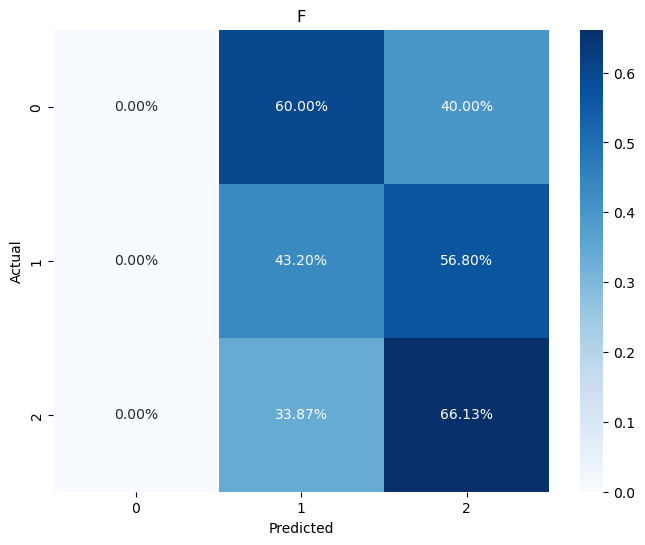

In [94]:
conf_matrix = confusion_matrix(y_test, y_pred0)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_percentage, annot=True, fmt='.2%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('F')
plt.show()

In [71]:
from sklearn.naive_bayes import GaussianNB

In [52]:
X = processed_features_df.drop(drop_features, axis=1)
y = processed_features_df[target_feature]

In [56]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import RFE


In [54]:
model=DecisionTreeClassifier()

In [57]:
rfe = RFE(model, n_features_to_select=20)  

rfe.fit(X, y)

selected_features_mask = rfe.support_

print(selected_features_mask)


[ True False False False  True False  True False False False False False
 False False False  True False False False False False False False  True
 False False False False False False False False False False False  True
 False False False False  True False False False False False False False
 False False False False False False  True False  True False False False
 False False False False False  True  True  True False False  True False
 False  True False False False False False False False False False False
 False False False False  True  True  True False False False False False
  True False False False  True False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False  True
 False False False False False False False False False]


In [58]:
X.columns[selected_features_mask]

Index(['temperature_stat_4', 'temperature_xt_jerk_8', 'temperature_xf_jerk_5',
       'humidity_xf_jerk_9', 'CO2CosIRValue_stat_9', 'CO2CosIRValue_xf_jerk_5',
       'CO2CosIRValue_xf_jerk_14', 'MOX1_stat_5', 'MOX1_stat_7',
       'MOX1_tm_dom_17', 'MOX1_xf_jerk_2', 'MOX1_xf_jerk_5', 'MOX1_xf_jerk_12',
       'MOX1_xf_jerk_15', 'MOX4_tm_dom_17', 'MOX4_xf_jerk_2', 'MOX4_xf_jerk_5',
       'MOX4_xf_jerk_15', 'COValue_stat_6', 'COValue_xf_jerk_11'],
      dtype='object')

In [59]:
x=X[X.columns[selected_features_mask]]

In [60]:
x.shape

(1531, 20)

In [61]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=903)

In [62]:
from sklearn.metrics import accuracy_score, confusion_matrix

In [63]:
model2 = DecisionTreeClassifier(max_depth=3)
model2.fit(X_train,y_train)
y_pred=model2.predict(X_test)

In [64]:
accuracy = accuracy_score(y_test, y_pred)
#report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")


Accuracy: 0.69


In [96]:
from imblearn.over_sampling import SMOTE
from collections import Counter

In [66]:
smote = SMOTE(random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

In [67]:
model2 = DecisionTreeClassifier(max_depth=3)
model2.fit(X_train,y_train)
y_pred=model2.predict(X_test)

In [68]:
accuracy = accuracy_score(y_test, y_pred)
#report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.41


In [253]:
features_corr_df = pd.DataFrame(processed_features_df.corr())
features_corr_df

/var/folders/j2/mxbl1d3s7wqdbntq3mdbcgh00000gn/T/ipykernel_46911/2660981957.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  features_corr_df = pd.DataFrame(processed_features_df.corr())


,temperature_stat_4,temperature_stat_5,temperature_xt_jerk_0,temperature_xt_jerk_4,temperature_xt_jerk_8,temperature_xt_jerk_9,temperature_xf_jerk_5,temperature_xf_jerk_9,temperature_xf_jerk_11,humidity_stat_5,...,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,Living room,Bedroom,Bathroom,Kitchen,Hallway,total_count
temperature_stat_4,1.000000,0.049079,0.094028,-0.035033,0.065057,0.059428,-0.011651,0.060158,0.012514,0.037377,...,-0.014594,-0.014948,-0.015311,-0.014104,-0.048436,-0.074299,-0.039723,-0.051135,-0.060788,-0.069987
temperature_stat_5,0.049079,1.000000,0.032528,-0.051788,0.020575,-0.095279,-0.076162,-0.094717,-0.160049,0.181604,...,-0.022343,-0.021438,-0.021549,-0.020394,-0.031070,0.095815,-0.018957,-0.057526,-0.026246,-0.016267
temperature_xt_jerk_0,0.094028,0.032528,1.000000,0.167948,0.854645,-0.048176,-0.001351,-0.047234,-0.095400,0.005563,...,-0.089255,-0.093331,-0.091007,-0.092501,-0.031009,0.051490,0.015415,-0.050625,-0.015026,-0.009761
temperature_xt_jerk_4,-0.035033,-0.051788,0.167948,1.000000,0.181324,-0.014768,0.043613,-0.014560,-0.026358,-0.031273,...,0.007133,0.006380,0.004677,0.003824,-0.019420,0.032133,0.012648,-0.028469,-0.030434,-0.011755
temperature_xt_jerk_8,0.065057,0.020575,0.854645,0.181324,1.000000,-0.077101,0.002013,-0.076231,-0.127524,0.013605,...,-0.091603,-0.095492,-0.092928,-0.095123,-0.018722,0.074867,0.041374,-0.053231,-0.001418,0.010572
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Bedroom,-0.074299,0.095815,0.051490,0.032133,0.074867,-0.136141,-0.015930,-0.136632,-0.102323,0.054740,...,-0.021606,-0.021919,-0.018592,-0.018592,0.216998,1.000000,0.291388,-0.137675,0.227650,0.400648
Bathroom,-0.039723,-0.018957,0.015415,0.012648,0.041374,0.019530,0.076352,0.020088,-0.015654,-0.023394,...,0.079171,0.076564,0.075674,0.076974,0.601188,0.291388,1.000000,0.153613,0.692605,0.811207
Kitchen,-0.051135,-0.057526,-0.050625,-0.028469,-0.053231,0.109727,0.045557,0.109124,0.076233,-0.044197,...,0.143721,0.142897,0.142251,0.137694,0.370756,-0.137675,0.153613,1.000000,0.335234,0.407349
Hallway,-0.060788,-0.026246,-0.015026,-0.030434,-0.001418,0.057242,0.051401,0.056908,0.029784,-0.035480,...,0.141901,0.135011,0.137322,0.137232,0.825525,0.227650,0.692605,0.335234,1.000000,0.921211


In [60]:
X = processed_features_df.drop(drop_features, axis=1)
y = processed_features_df[target_feature]

In [54]:
from sklearn.feature_selection import RFE
import xgboost as xgb

In [67]:
model = xgb.XGBClassifier()

rfe = RFE(model, n_features_to_select=10)  

# Fit RFE
rfe.fit(X, y)


# Get selected features mask
selected_features_mask = rfe.support_

# Select features using the mask
selected_features = X[:, selected_features_mask]

print("Selected Features:")
print(selected_features)

InvalidIndexError: (slice(None, None, None), array([False, False, False, False, False, False, False, False, False,
       False, False, False, False,  True, False,  True, False, False,
       False, False, False, False, False,  True, False, False, False,
       False,  True, False, False, False, False, False, False,  True,
       False, False, False, False,  True,  True, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False,  True, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False,  True, False,
       False, False, False, False, False, Fal

In [68]:
column__with_corr = features_corr_df.columns[(abs(features_corr_df['total_count']))>0.05]
column__with_corr = list(column__with_corr)
len(column__with_corr), column__with_corr

NameError: name 'features_corr_df' is not defined

In [255]:
features_corr_df = pd.DataFrame(processed_features_df[column__with_corr].corr())
features_corr_df

,CO2CosIRValue_stat_3,CO2CosIRValue_stat_6,CO2CosIRValue_stat_7,CO2CosIRValue_stat_9,CO2CosIRValue_xt_jerk_9,CO2CosIRValue_tm_dom_9,CO2CosIRValue_tm_dom_12,CO2CosIRValue_tm_dom_13,CO2CosIRValue_tm_dom_14,CO2CosIRValue_tm_dom_15,...,COValue_xf_jerk_17,COValue_xf_jerk_18,COValue_xf_jerk_19,COValue_xf_jerk_20,Living room,Bedroom,Bathroom,Kitchen,Hallway,total_count
CO2CosIRValue_stat_3,1.000000,0.948293,0.901183,0.425742,0.826083,0.425777,0.969546,0.870739,0.943233,0.811804,...,0.613530,0.614166,0.612065,0.603506,0.213575,0.059666,0.113746,0.172152,0.189530,0.208941
CO2CosIRValue_stat_6,0.948293,1.000000,0.938481,0.435061,0.750005,0.435126,0.958458,0.747190,0.909597,0.727625,...,0.552685,0.554069,0.552120,0.550534,0.179338,0.062142,0.104211,0.136962,0.164340,0.180767
CO2CosIRValue_stat_7,0.901183,0.938481,1.000000,0.414686,0.706908,0.414750,0.904557,0.698914,0.864334,0.701003,...,0.567689,0.571332,0.570226,0.567527,0.188210,0.045710,0.104727,0.164898,0.172019,0.187677
CO2CosIRValue_stat_9,0.425742,0.435061,0.414686,1.000000,0.337276,1.000000,0.432990,0.389186,0.365585,0.414437,...,0.311976,0.310667,0.313511,0.319356,0.272627,0.307147,0.115446,0.146792,0.215406,0.281059
CO2CosIRValue_xt_jerk_9,0.826083,0.750005,0.706908,0.337276,1.000000,0.337316,0.747569,0.728569,0.824106,0.635571,...,0.602584,0.606202,0.608132,0.579720,0.150536,0.061285,0.075064,0.134394,0.139879,0.153213
CO2CosIRValue_tm_dom_9,0.425777,0.435126,0.414750,1.000000,0.337316,1.000000,0.433033,0.389168,0.365636,0.414450,...,0.312004,0.310698,0.313542,0.319390,0.272594,0.307091,0.115435,0.146796,0.215379,0.281025
CO2CosIRValue_tm_dom_12,0.969546,0.958458,0.904557,0.432990,0.747569,0.433033,1.000000,0.809883,0.902598,0.756990,...,0.562800,0.563466,0.560635,0.555873,0.203007,0.062818,0.106428,0.149574,0.177604,0.196401
CO2CosIRValue_tm_dom_13,0.870739,0.747190,0.698914,0.389186,0.728569,0.389168,0.809883,1.000000,0.781709,0.748125,...,0.548223,0.549796,0.547167,0.528153,0.191261,0.076038,0.077485,0.179815,0.171244,0.188345
CO2CosIRValue_tm_dom_14,0.943233,0.909597,0.864334,0.365585,0.824106,0.365636,0.902598,0.781709,1.000000,0.729173,...,0.592966,0.593340,0.592380,0.579941,0.169651,0.035594,0.114817,0.151361,0.160258,0.176105
CO2CosIRValue_tm_dom_15,0.811804,0.727625,0.701003,0.414437,0.635571,0.414450,0.756990,0.748125,0.729173,1.000000,...,0.501585,0.502631,0.498649,0.495810,0.192299,0.098215,0.078510,0.155015,0.165741,0.187732


In [256]:
features_corr_df.columns

Index(['CO2CosIRValue_stat_3', 'CO2CosIRValue_stat_6', 'CO2CosIRValue_stat_7',
       'CO2CosIRValue_stat_9', 'CO2CosIRValue_xt_jerk_9',
       'CO2CosIRValue_tm_dom_9', 'CO2CosIRValue_tm_dom_12',
       'CO2CosIRValue_tm_dom_13', 'CO2CosIRValue_tm_dom_14',
       'CO2CosIRValue_tm_dom_15', 'CO2CosIRValue_tm_dom_16',
       'CO2CosIRValue_tm_dom_17', 'CO2CosIRValue_xf_jerk_2',
       'CO2CosIRValue_xf_jerk_9', 'CO2CosIRValue_xf_jerk_11',
       'CO2CosIRValue_xf_jerk_12', 'CO2CosIRValue_xf_jerk_13',
       'CO2CosIRValue_xf_jerk_14', 'CO2CosIRValue_xf_jerk_15',
       'COValue_stat_3', 'COValue_stat_7', 'COValue_stat_9',
       'COValue_xt_jerk_1', 'COValue_xt_jerk_3', 'COValue_tm_dom_6',
       'COValue_tm_dom_7', 'COValue_tm_dom_9', 'COValue_tm_dom_12',
       'COValue_tm_dom_13', 'COValue_tm_dom_14', 'COValue_xf_jerk_0',
       'COValue_xf_jerk_1', 'COValue_xf_jerk_3', 'COValue_xf_jerk_6',
       'COValue_xf_jerk_7', 'COValue_xf_jerk_8', 'COValue_xf_jerk_12',
       'COValue_xf_jerk

In [257]:
clmn = features_corr_df['total_count'].sort_values(ascending=False)
clmn_cor = list(clmn.index)
clmn_cor

['total_count',
 'Hallway',
 'Living room',
 'Bathroom',
 'Kitchen',
 'Bedroom',
 'CO2CosIRValue_stat_9',
 'CO2CosIRValue_tm_dom_9',
 'CO2CosIRValue_stat_3',
 'CO2CosIRValue_xf_jerk_12',
 'COValue_stat_9',
 'COValue_tm_dom_9',
 'CO2CosIRValue_tm_dom_12',
 'CO2CosIRValue_xf_jerk_13',
 'CO2CosIRValue_xf_jerk_15',
 'CO2CosIRValue_tm_dom_13',
 'CO2CosIRValue_tm_dom_15',
 'CO2CosIRValue_stat_7',
 'CO2CosIRValue_tm_dom_16',
 'CO2CosIRValue_stat_6',
 'CO2CosIRValue_tm_dom_17',
 'CO2CosIRValue_tm_dom_14',
 'CO2CosIRValue_xf_jerk_14',
 'CO2CosIRValue_xf_jerk_9',
 'CO2CosIRValue_xt_jerk_9',
 'COValue_tm_dom_13',
 'CO2CosIRValue_xf_jerk_11',
 'COValue_xf_jerk_13',
 'COValue_stat_7',
 'COValue_tm_dom_6',
 'CO2CosIRValue_xf_jerk_2',
 'COValue_xf_jerk_17',
 'COValue_xf_jerk_16',
 'COValue_xf_jerk_3',
 'COValue_xf_jerk_1',
 'COValue_xf_jerk_20',
 'COValue_xf_jerk_19',
 'COValue_xf_jerk_6',
 'COValue_xf_jerk_12',
 'COValue_xf_jerk_18',
 'COValue_tm_dom_7',
 'COValue_xt_jerk_3',
 'COValue_stat_3',
 'CO

In [258]:
# remove highly correlated variables
drop_list = []
keep_list = []
for clmn in column__with_corr:
    if not clmn in drop_list:
        clmns = features_corr_df.loc[clmn]
        clmns = list(clmns[clmns>0.8].index)

        if len(clmns) > 1:
            clmns = [x for x in clmns if x != clmn]
            drop_list.extend(clmns)
            
        keep_list.append(clmn)

In [259]:
len(drop_list), len(keep_list)

(41, 11)

In [260]:
keep_list.append('total_count')

In [261]:
keep_list

['CO2CosIRValue_stat_3',
 'CO2CosIRValue_stat_9',
 'CO2CosIRValue_xf_jerk_2',
 'CO2CosIRValue_xf_jerk_11',
 'CO2CosIRValue_xf_jerk_15',
 'COValue_stat_3',
 'COValue_stat_9',
 'Living room',
 'Bedroom',
 'Bathroom',
 'Kitchen',
 'total_count']

In [262]:
final_features_df = processed_features_df[keep_list].copy()
final_features_df.head()

,CO2CosIRValue_stat_3,CO2CosIRValue_stat_9,CO2CosIRValue_xf_jerk_2,CO2CosIRValue_xf_jerk_11,CO2CosIRValue_xf_jerk_15,COValue_stat_3,COValue_stat_9,Living room,Bedroom,Bathroom,Kitchen,total_count
0,5.107408,1.287863e+06,1.206958,6.838118,16.534914,2.159763,1.655114e+06,4.0,0.0,2.0,2.0,12.0
1,4.800259,1.220852e+06,0.799430,5.722147,12.055630,7.150332,2.255417e+06,0.0,0.0,0.0,2.0,2.0
2,3.026785,1.336974e+06,2.492270,3.248325,2.492270,3.128076,2.096573e+06,3.0,0.0,2.0,0.0,8.0
3,1.565296,1.368498e+06,0.225960,0.941840,3.768701,1.889792,2.107634e+06,3.0,0.0,2.0,0.0,9.0
4,4.889608,1.598136e+06,1.468163,1.468163,9.382751,3.467793,2.408751e+06,NaN,NaN,NaN,NaN,NaN


In [263]:
final_features_df.corr()

,CO2CosIRValue_stat_3,CO2CosIRValue_stat_9,CO2CosIRValue_xf_jerk_2,CO2CosIRValue_xf_jerk_11,CO2CosIRValue_xf_jerk_15,COValue_stat_3,COValue_stat_9,Living room,Bedroom,Bathroom,Kitchen,total_count
CO2CosIRValue_stat_3,1.000000,0.425742,0.741344,0.775610,0.729009,0.624107,0.404003,0.213575,0.059666,0.113746,0.172152,0.208941
CO2CosIRValue_stat_9,0.425742,1.000000,0.255298,0.320391,0.371503,0.366157,0.743029,0.272627,0.307147,0.115446,0.146792,0.281059
CO2CosIRValue_xf_jerk_2,0.741344,0.255298,1.000000,0.776809,0.555395,0.411343,0.250565,0.164286,0.027939,0.072729,0.134922,0.140819
CO2CosIRValue_xf_jerk_11,0.775610,0.320391,0.776809,1.000000,0.470160,0.469071,0.295301,0.150470,0.033377,0.088499,0.128676,0.146971
CO2CosIRValue_xf_jerk_15,0.729009,0.371503,0.555395,0.470160,1.000000,0.491683,0.324182,0.193068,0.094526,0.084015,0.161825,0.189078
COValue_stat_3,0.624107,0.366157,0.411343,0.469071,0.491683,1.000000,0.524445,0.135674,0.014225,0.064585,0.129575,0.132141
COValue_stat_9,0.404003,0.743029,0.250565,0.295301,0.324182,0.524445,1.000000,0.186922,0.170051,0.095305,0.125240,0.198188
Living room,0.213575,0.272627,0.164286,0.150470,0.193068,0.135674,0.186922,1.000000,0.216998,0.601188,0.370756,0.904805
Bedroom,0.059666,0.307147,0.027939,0.033377,0.094526,0.014225,0.170051,0.216998,1.000000,0.291388,-0.137675,0.400648
Bathroom,0.113746,0.115446,0.072729,0.088499,0.084015,0.064585,0.095305,0.601188,0.291388,1.000000,0.153613,0.811207


In [264]:
final_features_df.dropna(inplace=True)

In [265]:
final_features_df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1531 entries, 0 to 2287
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CO2CosIRValue_stat_3      1531 non-null   float64
 1   CO2CosIRValue_stat_9      1531 non-null   float64
 2   CO2CosIRValue_xf_jerk_2   1531 non-null   float64
 3   CO2CosIRValue_xf_jerk_11  1531 non-null   float64
 4   CO2CosIRValue_xf_jerk_15  1531 non-null   float64
 5   COValue_stat_3            1531 non-null   float64
 6   COValue_stat_9            1531 non-null   float64
 7   Living room               1531 non-null   float64
 8   Bedroom                   1531 non-null   float64
 9   Bathroom                  1531 non-null   float64
 10  Kitchen                   1531 non-null   float64
 11  total_count               1531 non-null   float64
dtypes: float64(12)
memory usage: 155.5 KB


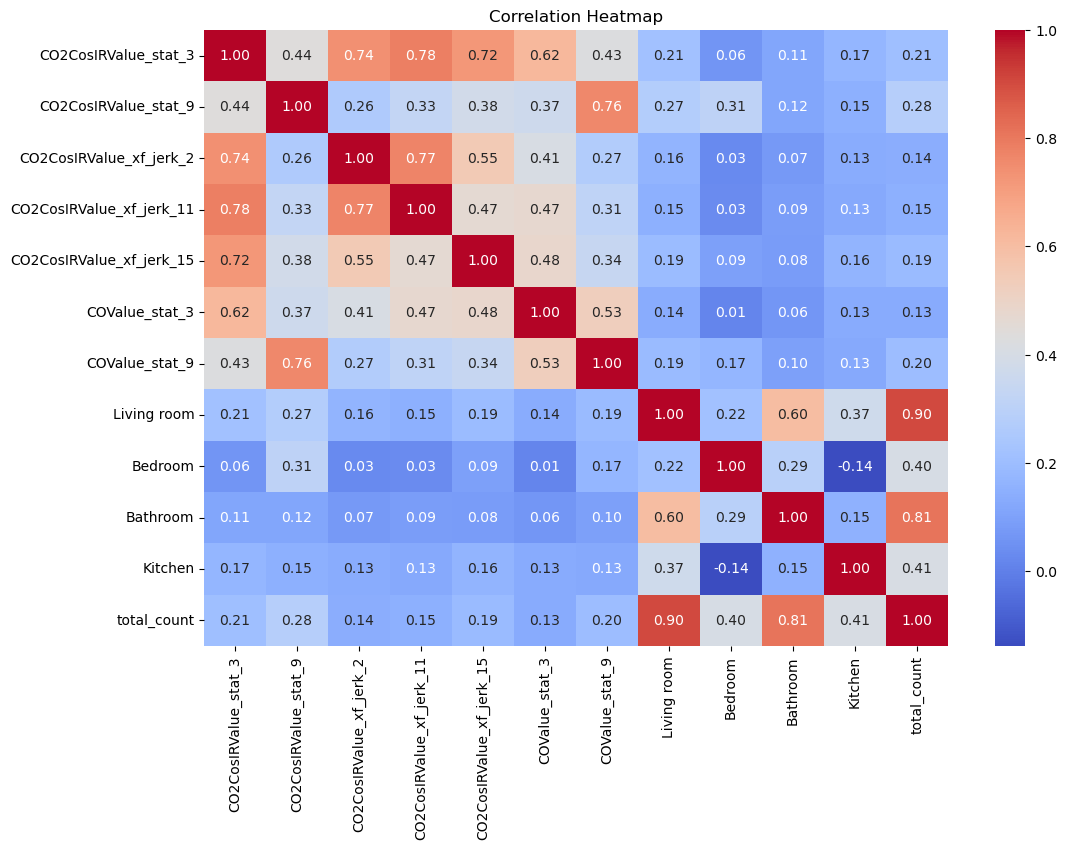

In [266]:
import seaborn as sns
correlation_matrix = final_features_df.corr()

# Create a heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

In [268]:
final_features_df.to_csv('Predicted_processed_v3.csv')

In [95]:
gas=pd.read_csv('Gas_final_data_v11.csv')

In [70]:
drop_features = ['Living room', 'Bedroom', 'Bathroom', 'Kitchen', 'total_count', 'timestamp','Hallway']
target_feature = 'total_count'

In [71]:
X = final_features_df.drop(drop_features, axis=1)
X = X.values
y = final_features_df[target_feature].values

In [72]:

regr = RandomForestRegressor(max_depth=4, random_state=0, n_estimators=30)
regr.fit(X, y)
regr.score(X, y)


0.25901078094276797

In [73]:
X.shape

(1534, 22)

In [74]:
from sklearn.metrics import mean_squared_error
y_pred = regr.predict(X)
mean_squared_error(y, y_pred)

43.62284846435696

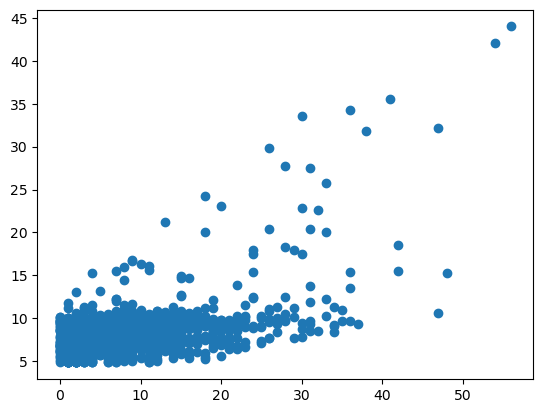

In [75]:
plt.scatter(y, y_pred)

In [76]:
from xgboost import XGBRegressor

In [77]:
my_model = XGBRegressor(n_estimators=15, learning_rate=1)

In [78]:
my_model.fit(X, y)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=15, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [79]:
y_pred = my_model.predict(X)

In [80]:
my_model.score(X, y)

0.9273848426397643

In [81]:
mean_squared_error(y, y_pred)

4.274933999405915

In [82]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.25,random_state=8)

In [83]:
my_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             gamma=None, grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=1, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=None, max_leaves=None,
             min_child_weight=None, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=15, n_jobs=None,
             num_parallel_tree=None, random_state=None, ...)

In [84]:
my_model.score(X_train,y_train)

0.9764768256483797

In [85]:
my_model.score(X_test,y_test)

-0.6955101739104854

In [86]:
y_pred_train=my_model.predict(X_train)

In [87]:
y_test

array([ 1.,  1., 12.,  2., 12., 11.,  7., 26., 11., 10.,  4.,  1., 24.,
        2.,  7., 29., 24.,  4.,  7., 12.,  1., 21.,  2., 10.,  9., 10.,
        2.,  6.,  7.,  1., 15.,  2., 33., 15., 11.,  2.,  3.,  9.,  7.,
       26.,  1.,  3.,  3.,  3.,  6.,  3.,  1., 13.,  9., 10., 10., 10.,
        8.,  9.,  7., 14.,  1., 16.,  6.,  6.,  1., 15.,  1.,  7.,  1.,
       14.,  2.,  5.,  1., 32.,  1.,  2.,  3., 19., 14.,  8., 12.,  8.,
        1.,  5.,  7., 34., 13.,  0., 11.,  7.,  1., 14.,  9.,  1.,  8.,
        2.,  4.,  7.,  1.,  3., 26., 13., 12.,  1.,  1.,  2., 27.,  3.,
        3., 11., 15., 11., 14., 15., 10., 22., 12., 13.,  1.,  4., 11.,
        4.,  3., 11.,  7., 34.,  7.,  7., 12.,  1.,  4.,  2.,  0., 20.,
        4., 11., 14.,  1., 10.,  8.,  3., 11.,  8.,  9.,  5.,  1., 13.,
        2.,  0., 23.,  4., 11.,  9.,  1.,  1., 34.,  1.,  4., 16.,  1.,
        7., 14.,  3.,  1.,  6., 22.,  1.,  1.,  2., 29., 10., 13.,  3.,
       11.,  3.,  4.,  0.,  8., 10., 10., 10.,  7.,  4., 11.,  8

In [88]:
y_pred=my_model.predict(X_test)

In [89]:
y_pred

array([ 2.75285339e+00,  1.02960262e+01,  8.11265945e+00,  5.62212944e+00,
        2.07153988e+01, -1.46995574e-01,  5.76129818e+00,  9.77289391e+00,
        1.03143787e+01,  1.41594448e+01,  1.08007920e+00,  6.78584623e+00,
        2.89967918e+00,  3.53759956e+00, -4.05869246e+00,  6.02974081e+00,
        3.47617378e+01,  1.48190031e+01,  1.36577682e+01,  3.79245114e+00,
        5.42354250e+00,  7.74372387e+00,  7.74084377e+00,  2.85286102e+01,
        5.73170424e+00,  1.08228798e+01,  6.20962381e+00,  4.77316380e+00,
        1.21932240e+01,  7.56279850e+00,  7.87356043e+00,  2.44928598e+00,
        4.65720606e+00,  1.20770817e+01,  7.45910549e+00,  9.69599438e+00,
       -1.89266324e-01,  1.56446190e+01,  1.88353004e+01,  6.52772713e+00,
        8.07015038e+00,  1.31708393e+01,  2.32949066e+00,  3.41533852e+00,
        1.09314651e+01,  1.13154256e+00, -8.94742393e+00,  1.06767178e+01,
       -2.28186417e+00,  3.75212169e+00,  1.72268543e+01,  8.37851143e+00,
        1.37551861e+01,  

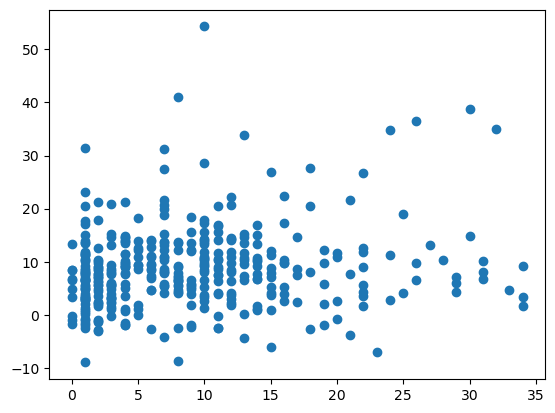

In [90]:
plt.scatter(y_test, y_pred)

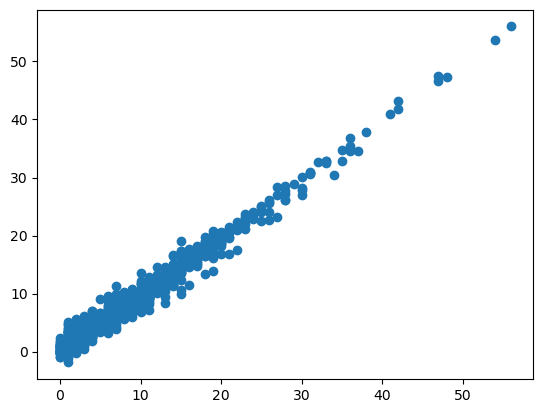

In [91]:
plt.scatter(y_train, y_pred_train)

In [92]:
from sklearn.model_selection import cross_val_score
cross_val_score(XGBRegressor(n_estimators=15, learning_rate=1), X, y,cv=5)

array([-1.00052861, -0.58869875, -0.42746742, -1.12244411, -0.25197615])

In [325]:
test_df.to_csv('final_data')

In [82]:
X.shape

(1531, 4)

In [83]:
from sklearn.svm import SVR
regressor = SVR(kernel = 'rbf')
regressor.fit(X, y)

SVR()

In [85]:
regressor.score(X,y)

0.04919310062277482